In [1]:
from torchvision.models import MobileNet_V3_Large_Weights

weights = MobileNet_V3_Large_Weights.DEFAULT

print(weights.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [2]:
from torchvision import transforms

IMAGE_SIZE = 512

normalize = transforms.Normalize(
    mean=weights.transforms().mean,
    std=weights.transforms().std
)

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    normalize
])

In [3]:
from pathlib import Path
from torchvision import datasets

DATA_DIR = Path("../dataset/Original CT Scans")

dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=transform
)

image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", dataset.classes[label])
print("Pixel tensor dtype:", image.dtype)

Image shape: torch.Size([3, 512, 512])
Label: NiCT
Pixel tensor dtype: torch.float32


In [4]:
from sklearn.model_selection import train_test_split
import numpy as np
from torch.utils.data import Subset


indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_indices]
)

train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())
test_dataset = Subset(dataset, test_indices.tolist())

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 13779
Validation: 2953
Test: 2953


In [5]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 862
Validation batches: 185
Test batches: 185


In [6]:
from torchvision import transforms

IMAGE_SIZE = 512

data_transforms = {
    "train": transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ]),

    "eval": transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])
}

In [8]:
from torchvision import datasets
from torch.utils.data import DataLoader, Subset

base_dataset = datasets.ImageFolder(
    root=str(DATA_DIR)
)

train_dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=data_transforms["train"]
)

eval_dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=data_transforms["eval"]
)

train_dataset = Subset(train_dataset, train_indices.tolist())
val_dataset = Subset(eval_dataset, val_indices.tolist())
test_dataset = Subset(eval_dataset, test_indices.tolist())

In [ ]:
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
import torch.nn as nn

weights = MobileNet_V3_Large_Weights.DEFAULT

model = mobilenet_v3_large(weights=weights)

in_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(in_features, 3)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\Agent89/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


100.0%


Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=3, bias=True)
)


In [10]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

total_params = sum(param.numel() for param in model.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")

Trainable parameters: 1,233,923
Total parameters: 4,205,875


## Model Training

## 1. Pretrained Weights and Image Preprocessing

Load the pretrained MobileNetV3-Large weights and inspect the preprocessing transformations associated with them.

In [13]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [14]:
train_loss, train_accuracy = train_one_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device
)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.2%}")

Training Loss: 0.1741
Training Accuracy: 93.63%


## Model Evaluation

Evaluate the model on the validation set without updating its weights.

In [15]:
def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [16]:
val_loss, val_accuracy = evaluate_model(
    model,
    val_loader,
    criterion,
    device
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2%}")

Validation Loss: 0.0670
Validation Accuracy: 98.04%


## Multi-Epoch Training

Train the model for multiple epochs and monitor training and validation performance to track learning progress and detect potential overfitting.

In [25]:
import time

NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(2, NUM_EPOCHS):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%} | "
        f"Time: {elapsed / 60:.1f} min"
    )

Epoch [3/5] | Train Loss: 0.0559 | Train Acc: 98.06% | Val Loss: 0.0426 | Val Acc: 98.65% | Time: 2.9 min
Epoch [4/5] | Train Loss: 0.0487 | Train Acc: 98.26% | Val Loss: 0.0400 | Val Acc: 98.75% | Time: 2.9 min
Epoch [5/5] | Train Loss: 0.0429 | Train Acc: 98.40% | Val Loss: 0.0483 | Val Acc: 98.75% | Time: 2.8 min


## Final Model Evaluation

Evaluate the trained model on the independent test set using accuracy, precision, recall, F1-score, and a confusion matrix.

In [26]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes,
    digits=4
))

              precision    recall  f1-score   support

        NiCT     0.9712    0.9836    0.9774       856
         nCT     0.9926    0.9806    0.9866      1497
         pCT     0.9835    0.9950    0.9892       600

    accuracy                         0.9844      2953
   macro avg     0.9824    0.9864    0.9844      2953
weighted avg     0.9845    0.9844    0.9844      2953



### Confusion Matrix

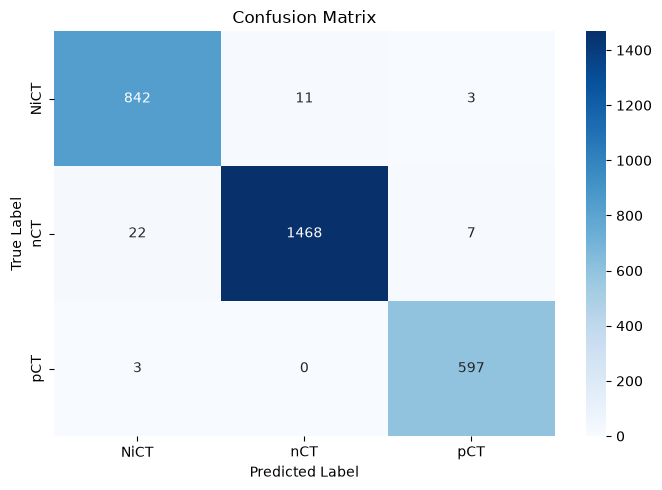

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dataset.classes,
    yticklabels=dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Training and Validation Curves

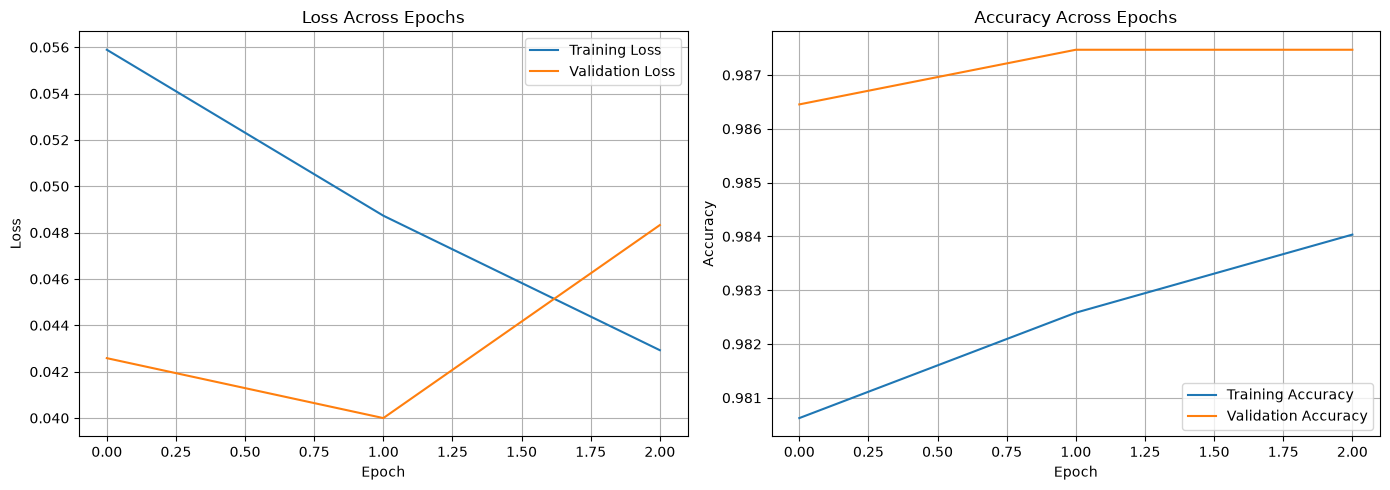

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history["train_loss"], label="Training Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["train_accuracy"], label="Training Accuracy")
axes[1].plot(history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Save Trained Model

In [35]:
from pathlib import Path
import torch

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": dataset.classes,
        "image_size": IMAGE_SIZE,
    },
    MODEL_DIR / "mobilenet_v3_ct.pth"
)

print("Model saved successfully.")

Model saved successfully.


### Verify Saved Model

In [36]:
checkpoint = torch.load(
    MODEL_DIR / "mobilenet_v3_ct.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Model checkpoint loaded successfully.")
print("Classes:", checkpoint["class_names"])
print("Image size:", checkpoint["image_size"])

Model checkpoint loaded successfully.
Classes: ['NiCT', 'nCT', 'pCT']
Image size: 512


## Single Image Prediction

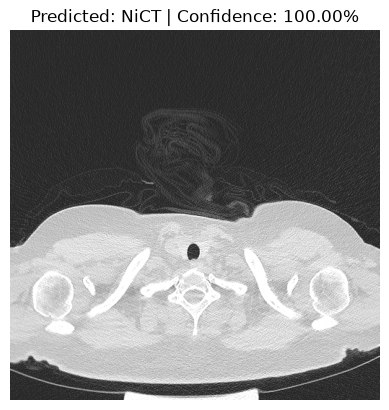

Predicted class: NiCT
Confidence: 100.00%


In [37]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

image_path = test_dataset.dataset.samples[test_dataset.indices[0]][0]

image = Image.open(image_path).convert("RGB")

input_tensor = test_dataset.dataset.transform(image).unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_idx = outputs.argmax(dim=1).item()

class_names = checkpoint["class_names"]
predicted_class = class_names[predicted_idx]
confidence = probabilities[0][predicted_idx].item() * 100

plt.imshow(image)
plt.axis("off")
plt.title(
    f"Predicted: {predicted_class} | Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")